In [1]:
from __future__ import annotations

from typing import TYPE_CHECKING

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

if TYPE_CHECKING:
    from collections.abc import Sequence

In [2]:
class Estimator:
    def __init__(self) -> None:
        self.alpha = None
        self.beta = None
        self.p_hat = None

    def initiate_prior(self, alpha: float, beta: float, *, plot: bool = True) -> None:
        self.alpha = alpha
        self.beta = beta
        self.history = np.array([])
        if plot:
            x = np.linspace(0, 1, 1000)
            y = stats.beta.pdf(x, self.alpha, self.beta)
            plt.plot(x, y)
            plt.fill_between(x, y, alpha=0.3)
            plt.title("Prior Distribution")
            plt.xlim(0, 1)
            plt.ylim(0, max(y) * 1.1)
            plt.show()

    def compute_posterior(
        self,
        obs: Sequence[int] | np.ndarray,
        *,
        plot: bool = True,
    ) -> None:
        assert self.alpha is not None, "Initiate prior before computing posterior"
        assert self.beta is not None, "Initiate prior before computing posterior"

        self.history = np.concatenate((self.history, np.asarray(obs).flatten()))
        self.alpha = self.alpha + np.sum(obs)
        self.beta = self.beta + len(obs) - np.sum(obs)
        self.p_hat = np.sum(self.history) / len(self.history)
        if plot:
            x = np.linspace(0, 1, 1000)
            y = stats.beta.pdf(x, self.alpha, self.beta)
            plt.plot(x, y)
            plt.fill_between(x, y, alpha=0.3)
            plt.axvline(x=self.p_hat, color='r', linestyle='--')
            plt.title("Posterior Distribution")
            plt.xlim(0, 1)
            plt.ylim(0, max(y) * 1.1)
            plt.show()

            print(self.history)

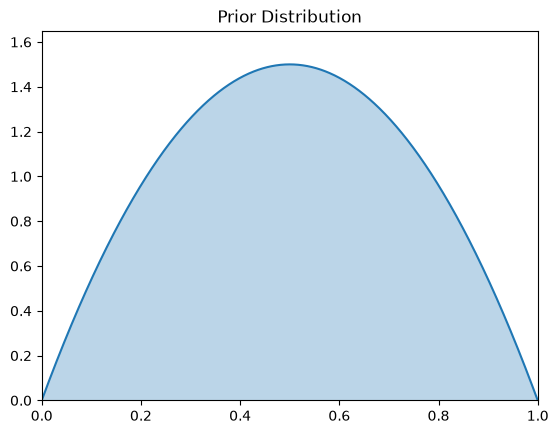

In [3]:
model = Estimator()
model.initiate_prior(alpha=2, beta=2)

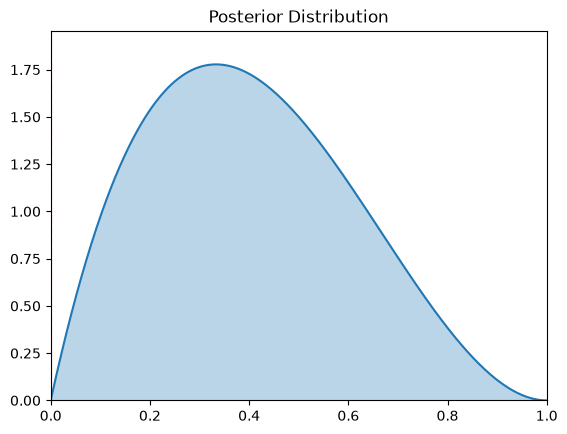

[0.]


In [4]:
model.compute_posterior([0])

In [5]:
model.p_hat

np.float64(0.0)